## Bayesian inference example for WL only

### 1. Preparation of data vectors

In [2]:
import numpy as np
import tensorflow as tf

In [1]:
# Necessary imports #

import sys
import os
os.environ["OMP_NUM_THREADS"] = "1"
#os.environ["OPENBLAS_NUM_THREADS"] = "1"
#os.environ["MKL_NUM_THREADS"] = "1"#
#os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
#os.environ["NUMEXPR_NUM_THREADS"] = "1"

import numpy as np
from scipy.interpolate import interp1d
from scipy import integrate
from copy import deepcopy
from multiprocessing import get_context
import time
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, RationalQuadratic, ExpSineSquared,
    DotProduct, ConstantKernel as C
)
import seaborn as sns
import matplotlib.pyplot as plt

from nautilus import Prior
from nautilus import Sampler
from scipy.stats import norm

# Import euclidlib for reading the Euclid data
import euclidlib as el

# Import cloelib for cosmology and theoretical predictions
from cloelib.cosmology.camb_cosmology import CAMBBackground
from cloelib.observables.photo import ShearTracer, PositionsTracer
from cloelib.summary_statistics.angular_two_point import AngularTwoPoint
from cloelib.cosmology.HMcode2020Emu_cosmology import HMemuLinearPerturbations, HMemuNonLinearPerturbations

# Import cloelike for likelihoods
from cloelike.EuclidLikelihood_photo_Cls import EuclidLikelihood_3x2pt
from cloelike.EuclidLikelihood_photo_Cls import EuclidLikelihood_WL

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(repo_root)

from binz.run_gp import build_gp_nz

2026-01-21 15:30:29.079162: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


/home/jipdebuck/miniconda3/envs/venv_310/lib/python3.10/site-packages/HMcode2020Emu
Loading linear emulator...


2026-01-21 15:30:31.514897: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Linear emulator loaded in memory.
Loading nonlinear emulator...
Non-linear emulator loaded in memory.
Loading linear emulator...
Baryonic boost emulator loaded in memory.
Loading sigma8 emulator...
Linear emulator loaded in memory.


In [2]:
# Load necessary files #

# We read with euclidlib v2025.2 (v2025.1 is also compatible)

name_to_chain = 'checkpoint_WL_DR1_first_try_area_2000_realistic'
name_to_chain_gp = 'checkpoint_gp'

#cells_data = el.photo.harmonic_space.angular_power_spectra('/disks/shear16/canasherrera/SheariouslyCalibrated/data/DR1/synthetic_angular_spectra_DR1.fits')
full_cov=np.load('/home/jipdebuck/covariance_Gauss_DR1_TR1like_1589_2D.npz')['Gauss']

# Get n(z)
z_nz, nz_heracles = el.phz.redshift_distributions('/home/jipdebuck/nz_example.fits')

In [3]:
# Normalize and resample n(z)'s #

myz = np.linspace(1e-4, 3.0, 100)
def normalize_dndz(nz_example, z_nz):
    normalized = {}
    for key in nz_example:
        normalized[key] = nz_example[key] / integrate.trapezoid(nz_example[key], z_nz)
    return normalized

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz_heracles, z_nz)
dndz_she_norm = normalize_dndz(nz_heracles, z_nz)

# Function to resample the normalized dndz
def resample_dndz(nz_example, z_nz, myz):
    my_dndz = np.vstack(list(nz_example.values())) #stacking arrays vertically
    my_dndz_norm = np.zeros([len(nz_example), len(myz)]) #creating an empty array
    for i in range(len(nz_example)):
        my_dndz_norm[i, :] = np.interp(myz, z_nz, my_dndz[i, :]) #interpolating to new myz values
    return my_dndz_norm

my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z_nz, myz)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z_nz, myz)

In [57]:
# Define fiducial parameters and ell vector #

fiducial_cosmology = {
    'H0': 67,                # Hubble constant
    'Omega_cdm0': 0.27,        # Cold dark matter density
    'Omega_b0': 0.049,         # Baryon density
    'Omega_k0': 0.0,           # Curvature
    'mnu': 0.077,                # Neutrino mass
    'w0': -1.0,                # Dark energy equation of state (present)
    'wa': 0.0,                 # Dark energy equation of state (evolution)
    'ns': 0.96,                # Scalar spectral index
    'As': 2.1e-9, # Scalar amplitude
    'gamma_MG': 0.545,         # Modified gravity parameter
    'log10TAGN': 7.75,          # AGN feedback parameter
    'N_mnu': 1,                  # Number of massive neutrino species
    'N_eff': 3.046             # Effective number of relativistic species
}

fiducial_nuisance = {
    # Intrinsic alignment
    'AIA': 0.16, 'EtaIA': 1.66, 'CIA': 0.0134,
    # Galaxy bias (poly coefficients)
    'b1_photo_poly0': 1.33291, 'b1_photo_poly1': -0.72414, 
    'b1_photo_poly2': 1.0183, 'b1_photo_poly3': -0.14913,
    # Magnification bias (per bin)
    'magnification_bias_1': 0.0, 'magnification_bias_2': 0.0,
    'magnification_bias_3': 0.0, 'magnification_bias_4': 0.0,
    'magnification_bias_5': 0.0, 'magnification_bias_6': 0.0,
    'magnification_bias_7': 0.0, 'magnification_bias_8': 0.0,
    'magnification_bias_9': 0.0, 'magnification_bias_10': 0.0,
    'magnification_bias_11': 0.0, 'magnification_bias_12': 0.0,
    'magnification_bias_13': 0.0,
    # Redshift errors (positions)
    'dz_pos_1': 0.0, 'dz_pos_2': 0.0, 'dz_pos_3': 0.0, 
    'dz_pos_4': 0.0, 'dz_pos_5': 0.0, 'dz_pos_6': 0.0,
    'dz_pos_7': 0.0, 'dz_pos_8': 0.0, 'dz_pos_9': 0.0, 
    'dz_pos_10': 0.0, 'dz_pos_11': 0.0, 'dz_pos_12': 0.0,
    'dz_pos_13': 0.0,
    # Multiplicative shear bias
    'multiplicative_bias_1': 0.0, 'multiplicative_bias_2': 0.0,
    'multiplicative_bias_3': 0.0, 'multiplicative_bias_4': 0.0,
    'multiplicative_bias_5': 0.0, 'multiplicative_bias_6': 0.0,
    'multiplicative_bias_7': 0.0, 'multiplicative_bias_8': 0.0,
    'multiplicative_bias_9': 0.0, 'multiplicative_bias_10': 0.0,
    'multiplicative_bias_11': 0.0, 'multiplicative_bias_12': 0.0,
    'multiplicative_bias_13': 0.0,
    # Redshift errors (shear)
    'dz_shear_1': 0.0, 'dz_shear_2': 0.0, 'dz_shear_3': 0.0,
    'dz_shear_4': 0.0, 'dz_shear_5': 0.0, 'dz_shear_6': 0.0,
    'dz_shear_7': 0.0, 'dz_shear_8': 0.0, 'dz_shear_9': 0.0, 
    'dz_shear_10': 0.0, 'dz_shear_11': 0.0, 'dz_shear_12': 0.0,
    'dz_shear_13': 0.0
}

fiducial_gp = {'x1': 0.455, 'x2': 0.725, 'x3': 0.941, 'x4': 1.161, 'x5': 1.432, 'x6': 1.893, 'corr_len': 0.04}

ell_theory = np.array([
    10.97557970,
    13.11709027,
    15.67644367,
    18.73516773,
    22.39069761,
    26.75947964,
    31.98068069,
    38.22062129,
    45.67807378,
    54.59059412,
    65.24208925,
    77.97186088,
    93.18541388,
    111.36737359,
    133.09692347,
    159.06625492,
    190.10261691,
    227.19466787,
    271.52396925,
    324.50262398,
    387.81825878,
    463.48778323,
    553.92163814,
    662.00057974,
    791.16744571,
    945.53682628,
    1130.02613377,
    1350.51224608,
    1614.01871364,
    1928.93949355,
    2305.30633773,
    2755.10835283
])

In [5]:
# Compute cosmology #

# Choose which perturbation model to use: 'linear' or 'nonlinear'
perturbation_model = 'nonlinear'  # change to 'linear' if needed

# Cosmology parameters (easy to modify)
cosmo_params = fiducial_cosmology.copy()
nuisance_params = fiducial_nuisance.copy()

# Create background
background = CAMBBackground(
    H0=cosmo_params['H0'],
    Omega_cdm0=cosmo_params['Omega_cdm0'],
    Omega_b0=cosmo_params['Omega_b0'],
    w0=cosmo_params['w0'],
    wa=cosmo_params['wa'],
    Omega_k0=cosmo_params['Omega_k0'],
    ns=cosmo_params['ns'],
    As=cosmo_params['As'],
    mnu=cosmo_params['mnu'],
    gamma_MG=cosmo_params['gamma_MG'],
    N_mnu=cosmo_params['N_mnu']
)

# Choose perturbations
if perturbation_model == 'linear':
    perturbations = HMemuLinearPerturbations(background, myz)
else:
    perturbations = HMemuNonLinearPerturbations(
        background, 
        HMemuLinearPerturbations(background, myz), 
        myz, 
        log10TAGN=cosmo_params['log10TAGN']
    )

# Tracer definitions (only for cosmic shear)
tracer_pos = PositionsTracer(
    perturbations=perturbations,
    dndz=my_dndz_pos_norm,
    z=myz,
    galaxy_bias_model='poly',
    nuisance_params=nuisance_params
)

tracer_she = ShearTracer(
    perturbations=perturbations,
    dndz=my_dndz_she_norm,
    z=myz,
    nuisance_params=nuisance_params
)


In [6]:
# Compute the two-point angular power spectra #

cls_sheshe = AngularTwoPoint(tracer_she, tracer_she).get_Cl(ell_theory, 0, perturbations.k)
cls_posshe = AngularTwoPoint(tracer_pos, tracer_she).get_Cl(ell_theory, 0, perturbations.k)
cls_pospos = AngularTwoPoint(tracer_pos, tracer_pos).get_Cl(ell_theory, 0, perturbations.k)
print(cls_sheshe[('SHE', 'SHE', 1,1)], len(ell_theory))

# Combine all spectra into a single dictionary for easy access
uncoupled_cls = {**cls_posshe, **cls_sheshe, **cls_pospos}
uncoupled_cls_WL = {**cls_sheshe}
print(uncoupled_cls.keys())

AngularPowerSpectrum(axis=(2,)) 32
dict_keys([('POS', 'SHE', 1, 1), ('POS', 'SHE', 2, 1), ('POS', 'SHE', 1, 2), ('POS', 'SHE', 3, 1), ('POS', 'SHE', 1, 3), ('POS', 'SHE', 4, 1), ('POS', 'SHE', 1, 4), ('POS', 'SHE', 5, 1), ('POS', 'SHE', 1, 5), ('POS', 'SHE', 6, 1), ('POS', 'SHE', 1, 6), ('POS', 'SHE', 2, 2), ('POS', 'SHE', 3, 2), ('POS', 'SHE', 2, 3), ('POS', 'SHE', 4, 2), ('POS', 'SHE', 2, 4), ('POS', 'SHE', 5, 2), ('POS', 'SHE', 2, 5), ('POS', 'SHE', 6, 2), ('POS', 'SHE', 2, 6), ('POS', 'SHE', 3, 3), ('POS', 'SHE', 4, 3), ('POS', 'SHE', 3, 4), ('POS', 'SHE', 5, 3), ('POS', 'SHE', 3, 5), ('POS', 'SHE', 6, 3), ('POS', 'SHE', 3, 6), ('POS', 'SHE', 4, 4), ('POS', 'SHE', 5, 4), ('POS', 'SHE', 4, 5), ('POS', 'SHE', 6, 4), ('POS', 'SHE', 4, 6), ('POS', 'SHE', 5, 5), ('POS', 'SHE', 6, 5), ('POS', 'SHE', 5, 6), ('POS', 'SHE', 6, 6), ('SHE', 'SHE', 1, 1), ('SHE', 'SHE', 1, 2), ('SHE', 'SHE', 1, 3), ('SHE', 'SHE', 1, 4), ('SHE', 'SHE', 1, 5), ('SHE', 'SHE', 1, 6), ('SHE', 'SHE', 2, 2), ('SHE', 

In [7]:
# Slice the covariance to isolate WL part #

cov_WL = full_cov[:(21)*32, :(21)*32]

In [8]:
# Define functions to build the data vectors #

def build_data(cls, mapa_key, cov, zs, nzs, include_pos=False, include_she=False):
    data = {
        'cells': cls,
        'ells': cls[mapa_key].ell,
        'z_arr': zs,
        'cov': cov,
        'mixmat': {},
    }
    if include_pos:
        data['dndz_pos'] = nzs[0]
    if include_she:
        data['dndz_she'] = nzs[1]
    return data

def build_settings(cls):
    for key in cls:
        if key[:2] == ('POS', 'POS'):
            scale_cuts = {key: [10, 750] for key in cls}
        else:
            scale_cuts = {key: [10, 1500] for key in cls}
    return {'n_ell_bins': 32, 'scale_cuts': scale_cuts}

In [9]:
data_3x2pt  = build_data(uncoupled_cls, ('SHE', 'SHE', 1, 1), 
                             full_cov, 
                             myz, [my_dndz_pos_norm, my_dndz_she_norm],
                             include_pos=True, include_she=True)
settings_3x2pt  = build_settings(uncoupled_cls)

data_WL  = build_data(uncoupled_cls_WL, ('SHE', 'SHE', 1, 1), 
                             cov_WL, 
                             myz, [my_dndz_pos_norm, my_dndz_she_norm],
                             include_pos=False, include_she=True)
settings_WL  = build_settings(uncoupled_cls_WL)

In [11]:
like_instance = EuclidLikelihood_WL(
        data=data_WL,
        settings=settings_WL,
        Background=CAMBBackground,
        LinPerturbations=HMemuLinearPerturbations,
        NonLinPerturbations=HMemuNonLinearPerturbations,
        mode="uncoupled"

    )

loglike = like_instance.loglike(fiducial_cosmology | fiducial_nuisance)
print("✨ Log-likelihood at fiducial: ", loglike)


✨ Log-likelihood at fiducial:  0.0


### 2. Inference

In [12]:
# Set priors for sampled parameters (only Omega_cdm0 and H0) #

zmean_dr1 = np.array([0.4371, 0.726, 0.9424, 1.164, 1.437, 1.963])

# Set priors
prior = Prior()
#prior.add_parameter('Omega_b0', dist=(0.01, 0.1))
prior.add_parameter('Omega_cdm0', dist=(0.1, 0.8))
#prior.add_parameter('logAs', dist=(np.log(0.6e-9*1e10), np.log(5e-9*1e10)))
#prior.add_parameter('ns', dist=(0.6, 1.2))
prior.add_parameter('H0', dist=(50, 90))
#prior.add_parameter('AIA', dist=(-1, 1))
#prior.add_parameter('EtaIA', dist=(-5, 5))
#prior.add_parameter('w0', dist=(-3.0, -0.5))
#prior.add_parameter('wa', dist=(-3.0, 3.0))
#prior.add_parameter('b1_photo_poly0', dist=(-3.0, 3.0))
#prior.add_parameter('b1_photo_poly1', dist=(-3.0, 3.0))
#prior.add_parameter('b1_photo_poly2', dist=(-3.0, 3.0))
#prior.add_parameter('b1_photo_poly3', dist=(-3.0, 3.0))
#prior.add_parameter('multiplicative_bias_1', norm(loc=0.0, scale=0.01))
#prior.add_parameter('multiplicative_bias_2', norm(loc=0.0, scale=0.01))
#prior.add_parameter('multiplicative_bias_3', norm(loc=0.0, scale=0.01))
#prior.add_parameter('multiplicative_bias_4', norm(loc=0.0, scale=0.01))
#prior.add_parameter('multiplicative_bias_5', norm(loc=0.0, scale=0.01))
#prior.add_parameter('multiplicative_bias_6', norm(loc=0.0, scale=0.01)) 
#prior.add_parameter('magnification_bias_1', dist=(-2.0, 2.0))
#prior.add_parameter('magnification_bias_2', dist=(-2.0, 2.0))
#prior.add_parameter('magnification_bias_3', dist=(-2.0, 2.0))
#prior.add_parameter('magnification_bias_4', dist=(-2.0, 2.0))
#prior.add_parameter('magnification_bias_5', dist=(-2.0, 2.0))
#prior.add_parameter('magnification_bias_6', dist=(-2.0, 2.0))
#prior.add_parameter('dz_pos_1', norm(loc=0.0, scale=0.002*(1+zmean_dr1[0])))
#prior.add_parameter('dz_pos_2', norm(loc=0.0, scale=0.002*(1+zmean_dr1[1])))
#prior.add_parameter('dz_pos_3', norm(loc=0.0, scale=0.002*(1+zmean_dr1[2])))
#prior.add_parameter('dz_pos_4', norm(loc=0.0, scale=0.002*(1+zmean_dr1[3])))
#prior.add_parameter('dz_pos_5', norm(loc=0.0, scale=0.002*(1+zmean_dr1[4])))
#prior.add_parameter('dz_pos_6', norm(loc=0.0, scale=0.002*(1+zmean_dr1[5])))
#prior.add_parameter('dz_shear_1', norm(loc=0.0, scale=0.002*(1+zmean_dr1[0])))
#prior.add_parameter('dz_shear_2', norm(loc=0.0, scale=0.002*(1+zmean_dr1[1])))
#prior.add_parameter('dz_shear_3', norm(loc=0.0, scale=0.002*(1+zmean_dr1[2])))
#prior.add_parameter('dz_shear_4', norm(loc=0.0, scale=0.002*(1+zmean_dr1[3])))
#prior.add_parameter('dz_shear_5', norm(loc=0.0, scale=0.002*(1+zmean_dr1[4])))
#prior.add_parameter('dz_shear_6', norm(loc=0.0, scale=0.002*(1+zmean_dr1[5])))

print("✨ Prior set up completed.")
print("Parameters sampled: ", prior.keys)
print("Number of sampled parameters:", len(prior.keys))

✨ Prior set up completed.
Parameters sampled:  ['Omega_cdm0', 'H0']
Number of sampled parameters: 2


In [ ]:
# Perform nested sampling # 

default_pars = fiducial_cosmology | fiducial_nuisance

def like_Naut_test(param_dict):
    # Enforce physical prior on w0 + wa
#    if param_dict['w0'] + param_dict['wa'] > -1. / 3:
#        return (-np.inf, 0)

    pars_in = default_pars.copy()
    pars_in.update(param_dict)

    #h = pars_in['H0'] / 100.0
    #pars_in['Omega_cdm0'] = param_dict['omch2'] / h**2
    #pars_in['Omega_b0'] = param_dict['ombh2'] / h**2
    #pars_in['As'] = np.exp(param_dict['logAs']) * 1e-10

    return (like_instance.loglike(pars_in), like_instance.derived['sigma8_0'])

blob_vec     = [('sigma8_0', float)]

#if __name__ == '__main__':

#with get_context("spawn").Pool(10) as p:
sampler = Sampler(prior, like_Naut_test, 
        n_live=5000, 
        blobs_dtype=blob_vec,
            filepath=name_to_chain + '.h5', 
            resume=True)
t_start = time.time()
print('Starting sampling...')
sampler.run(verbose=True)
t_end = time.time()
total_seconds = t_end - t_start
days = int(total_seconds // 86400)
hours = int((total_seconds % 86400) // 3600)
minutes = int((total_seconds % 3600) // 60)
seconds = int(total_seconds % 60)
print(f'Total time: {days}d {hours}h {minutes}m {seconds}s')
print('Sampling finished!')
print('Saving chains...')

points, log_w, log_l, derived = sampler.posterior(return_blobs=True)

        # --- Sampled parameters ---
param_names = list(prior.keys)
chain_dict = {
            name: points[:, i]
            for i, name in enumerate(param_names)
        }

        # --- Derived parameters ---
derived_names = [name for name, _ in blob_vec]

derived_dict = {
            derived_names[0]: np.array([sample[0] for sample in derived])
        }

        # --- Save everything in a labelled way ---
np.savez_compressed(
            name_to_chain + '.npz',
            chain=chain_dict,
            derived=derived_dict,
            weights=log_w,
            logl=log_l,
            param_names=param_names,
            derived_names=derived_names
        )

print('Chains saved with name:', name_to_chain + '.npz')

In [ ]:
import corner
import matplotlib.pyplot as plt

name_to_chain = 'checkpoint_WL_DR1_first_try_area_2000_realistic'
data = np.load(name_to_chain + ".npz", allow_pickle=True)
chain_dict = data["chain"].item()   # dictionary
param_names = data["param_names"]
log_w = data["weights"]
points = np.column_stack([chain_dict[p] for p in param_names])
print(points)
corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=param_names, color='purple',
    plot_datapoints=False, range=np.repeat(0.999, points.shape[1]))

### 3. Generating $n(z)$ using GP

In [56]:
# Define parameters for GP reconstruction #

z_meds = []   # positions of median redshift for each bin
n_meds = []   # height of n(z) at median redshift for each bin

for key, nz in dndz_she_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z_nz, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z_nz)
    n_med = nz[np.argmin(np.abs(z_nz - z_med))]
    z_meds.append(z_med)
    n_meds.append(n_med)

corr_len = 0.04                              # correlation length for the GP kernel
z_bounds = (0,3)                              # bounds for the redshift
z_pred = np.linspace(0, 3, 400)       # prediction points for GP
alpha = 1e-8                                  # noise level during fitting 
kernel_class = Matern
nu = 1.5                                      # necessary for Matern only, defines smoothness 
const_value = 0.04                            # amplitude of constant kernel
const_bounds = (1e-4, 1.0)                    # bounds for constant kernel amplitude
print(z_meds)

[0.4552587449532811, 0.7252948553202659, 0.9405554434401697, 1.1613934055555377, 1.431847015462385, 1.893076192964457]


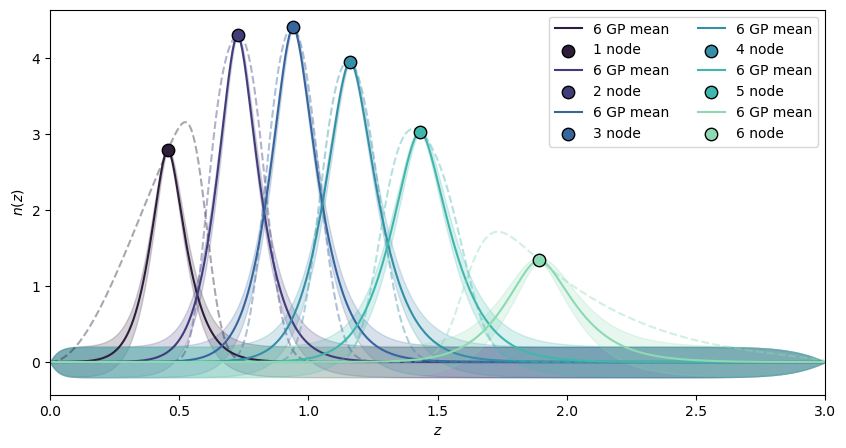

In [51]:
# GP reconstruction and plotting of results #

# Perform GP reconstruction #
priors, predictions = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)

# Plot GP reconstruction results #
palette = sns.color_palette("mako", 6)
fig, ax = plt.subplots(figsize=(10, 5))

for j, nz in enumerate(n_meds):
    y_pred, y_std = predictions[j]
    X_train, y_train = z_meds[j], n_meds[j]

    ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} GP mean")
    ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
                    color=palette[j], alpha=0.2)

    ax.plot(z_nz, dndz_she_norm[j+1], '--', color=palette[j], alpha=0.4)
    ax.scatter(X_train, y_train, color=palette[j], edgecolor='black', s=80, zorder=3, label=f"{j+1} node")

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(0, 3)
ax.legend(loc="upper right", ncol=2)
plt.show()


In [47]:
# Define a function to resample the reconstructed n(z) #

def resample_dndz_gp(gp_predictions, z_pred, zs):
    for key in gp_predictions.keys():
        gp_predictions[key] = gp_predictions[key][0]

    my_dndz = np.vstack(list(gp_predictions.values())) 
    my_dndz_norm = np.zeros([len(gp_predictions), len(zs)])
    for i in range(len(gp_predictions)):
        # gp_predictions[i][0] is 1D array of n(z) for bin i

        my_dndz_norm[i, :] = np.interp(zs, z_pred[:,0], my_dndz[i, :])
    return my_dndz_norm

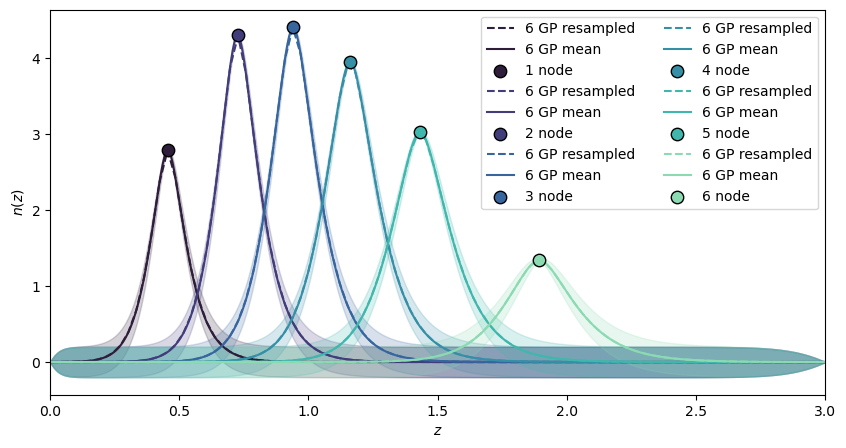

In [37]:
# Plotting the resampled GP n(z) together with original GP n(z) #

z_pred_res = z_pred.reshape(-1, 1)
predictions_sample = predictions.copy()
my_dndz_norm_gp = resample_dndz_gp(predictions_sample, z_pred_res, myz)
palette = sns.color_palette("mako", 6)
fig, ax = plt.subplots(figsize=(10, 5))

for j, nz in enumerate(n_meds):
    y_pred, y_std = predictions[j]
    X_train, y_train = z_meds[j], n_meds[j]
    ax.plot(myz, my_dndz_norm_gp[j], color=palette[j], linestyle='--',label=f"{key} GP resampled")
    ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} GP mean")
    ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
                    color=palette[j], alpha=0.2)

#    ax.plot(z_nz, dndz_she_norm[j+1], '--', color=palette[j], alpha=0.4)
    ax.scatter(X_train, y_train, color=palette[j], edgecolor='black', s=80, zorder=3, label=f"{j+1} node")

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(0, 3)
ax.legend(loc="upper right", ncol=2)
plt.show()


### 4. Sampling a single training node and the correlation length

In [15]:
# Set priors for sampled parameters (only Omega_cdm0 and H0) #

zmean_dr1 = np.array([0.4371, 0.726, 0.9424, 1.164, 1.437, 1.963])

# Set priors
prior_gp = Prior()
#prior.add_parameter('Omega_b0', dist=(0.01, 0.1))
#prior_gp.add_parameter('Omega_cdm0', dist=(0.1, 0.8))
#prior.add_parameter('logAs', dist=(np.log(0.6e-9*1e10), np.log(5e-9*1e10)))
#prior.add_parameter('ns', dist=(0.6, 1.2))
#prior_gp.add_parameter('H0', dist=(50, 90))
#prior.add_parameter('AIA', dist=(-1, 1))
#prior.add_parameter('EtaIA', dist=(-5, 5))
#prior.add_parameter('w0', dist=(-3.0, -0.5))
#prior.add_parameter('wa', dist=(-3.0, 3.0))
#prior.add_parameter('b1_photo_poly0', dist=(-3.0, 3.0))
#prior.add_parameter('b1_photo_poly1', dist=(-3.0, 3.0))
#prior.add_parameter('b1_photo_poly2', dist=(-3.0, 3.0))
#prior.add_parameter('b1_photo_poly3', dist=(-3.0, 3.0))
#prior.add_parameter('multiplicative_bias_1', norm(loc=0.0, scale=0.01))
#prior.add_parameter('multiplicative_bias_2', norm(loc=0.0, scale=0.01))
#prior.add_parameter('multiplicative_bias_3', norm(loc=0.0, scale=0.01))
#prior.add_parameter('multiplicative_bias_4', norm(loc=0.0, scale=0.01))
#prior.add_parameter('multiplicative_bias_5', norm(loc=0.0, scale=0.01))
#prior.add_parameter('multiplicative_bias_6', norm(loc=0.0, scale=0.01)) 
#prior.add_parameter('magnification_bias_1', dist=(-2.0, 2.0))
#prior.add_parameter('magnification_bias_2', dist=(-2.0, 2.0))
#prior.add_parameter('magnification_bias_3', dist=(-2.0, 2.0))
#prior.add_parameter('magnification_bias_4', dist=(-2.0, 2.0))
#prior.add_parameter('magnification_bias_5', dist=(-2.0, 2.0))
#prior.add_parameter('magnification_bias_6', dist=(-2.0, 2.0))
#prior.add_parameter('dz_pos_1', norm(loc=0.0, scale=0.002*(1+zmean_dr1[0])))
#prior.add_parameter('dz_pos_2', norm(loc=0.0, scale=0.002*(1+zmean_dr1[1])))
#prior.add_parameter('dz_pos_3', norm(loc=0.0, scale=0.002*(1+zmean_dr1[2])))
#prior.add_parameter('dz_pos_4', norm(loc=0.0, scale=0.002*(1+zmean_dr1[3])))
#prior.add_parameter('dz_pos_5', norm(loc=0.0, scale=0.002*(1+zmean_dr1[4])))
#prior.add_parameter('dz_pos_6', norm(loc=0.0, scale=0.002*(1+zmean_dr1[5])))
#prior.add_parameter('dz_shear_1', norm(loc=0.0, scale=0.002*(1+zmean_dr1[0])))
#prior.add_parameter('dz_shear_2', norm(loc=0.0, scale=0.002*(1+zmean_dr1[1])))
#prior.add_parameter('dz_shear_3', norm(loc=0.0, scale=0.002*(1+zmean_dr1[2])))
#prior.add_parameter('dz_shear_4', norm(loc=0.0, scale=0.002*(1+zmean_dr1[3])))
#prior.add_parameter('dz_shear_5', norm(loc=0.0, scale=0.002*(1+zmean_dr1[4])))
#prior.add_parameter('dz_shear_6', norm(loc=0.0, scale=0.002*(1+zmean_dr1[5])))
prior_gp.add_parameter('x1', dist= (0.2, 0.7))
prior_gp.add_parameter('corr_len', dist=(0.02, 0.1))

print("✨ Prior set up completed.")
print("Parameters sampled: ", prior_gp.keys)
print("Number of sampled parameters:", len(prior_gp.keys))

✨ Prior set up completed.
Parameters sampled:  ['x1', 'corr_len']
Number of sampled parameters: 2


In [ ]:

# Running the sampler #
# Here, we interrupt to save time #

default_pars = fiducial_cosmology | fiducial_nuisance
name_to_chain_gp = 'checkpoint_gp'

def like_Naut_test_gp(param_dict):
    # Enforce physical prior on w0 + wa
#    if param_dict['w0'] + param_dict['wa'] > -1. / 3:
#        return (-np.inf, 0)
    x1 = param_dict["x1"]
    l  = param_dict["corr_len"]
    z_meds[0] = x1
    priors_loop, predictions_loop = build_gp_nz(n_meds, z_meds, l, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)
    my_dndz_norm_gp_loop = resample_dndz_gp(predictions_loop, z_pred_res, myz)
    pars_in = default_pars.copy()
    pars_in.update(param_dict)
    #h = pars_in['H0'] / 100.0
    #pars_in['Omega_cdm0'] = param_dict['omch2'] / h**2
    #pars_in['Omega_b0'] = param_dict['ombh2'] / h**2
    #pars_in['As'] = np.exp(param_dict['logAs']) * 1e-10
    like_instance.data.update({'dndz_she': my_dndz_norm_gp_loop})
    return (like_instance.loglike(pars_in), like_instance.derived['sigma8_0'])

blob_vec     = [('sigma8_0', float)]

#if __name__ == '__main__':

#with get_context("spawn").Pool(10) as p:
sampler = Sampler(prior_gp, like_Naut_test_gp, 
        n_live=5000, 
        blobs_dtype=blob_vec,
            filepath=name_to_chain_gp + '.h5', 
            resume=True)
t_start = time.time()
print('Starting sampling...')
sampler.run(verbose=True)
t_end = time.time()
total_seconds = t_end - t_start
days = int(total_seconds // 86400)
hours = int((total_seconds % 86400) // 3600)
minutes = int((total_seconds % 3600) // 60)
seconds = int(total_seconds % 60)
print(f'Total time: {days}d {hours}h {minutes}m {seconds}s')
print('Sampling finished!')
print('Saving chains...')

points, log_w, log_l, derived = sampler.posterior(return_blobs=True)

        # --- Sampled parameters ---
param_names = list(prior.keys)
chain_dict = {
            name: points[:, i]
            for i, name in enumerate(param_names)
        }

        # --- Derived parameters ---
derived_names = [name for name, _ in blob_vec]

derived_dict = {
            derived_names[0]: np.array([sample[0] for sample in derived])
        }

        # --- Save everything in a labelled way ---
np.savez_compressed(
            name_to_chain_gp + '.npz',
            chain=chain_dict,
            derived=derived_dict,
            weights=log_w,
            logl=log_l,
            param_names=param_names,
            derived_names=derived_names
        )

print('Chains saved with name:', name_to_chain_gp + '.npz')

Starting sampling...
Resuming nautilus run...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    


KeyboardInterrupt: 

In [ ]:
# Checking whether likelihood returns different values for different GP parameters #

print(like_Naut_test_gp({'x1':0.4, 'corr_len':0.04}))
print(like_Naut_test_gp({'x1':0.5, 'corr_len':0.044}))
print(like_Naut_test_gp({'x1':0.4, 'corr_len':0.038}))

(-7.157396650948291, 0.8123578481137994)
(-27.3427529734711, 0.8123578481137994)
(-7.400794663945911, 0.8123578481137994)


### 5. Quick likelihood scan over cosmological and GP parameters


🔄 Scanning over x1


WL: 100%|███████████████████████████████████████| 50/50 [00:06<00:00,  7.93it/s]



🔄 Scanning over x2


WL: 100%|███████████████████████████████████████| 50/50 [00:05<00:00,  8.39it/s]



🔄 Scanning over x3


...

WL: 100%|███████████████████████████████████████| 50/50 [00:05<00:00,  8.42it/s]



🔄 Scanning over Omega_cdm0


WL: 100%|███████████████████████████████████████| 50/50 [00:05<00:00,  8.95it/s]



🔄 Scanning over H0


WL: 100%|███████████████████████████████████████| 50/50 [00:05<00:00,  9.02it/s]


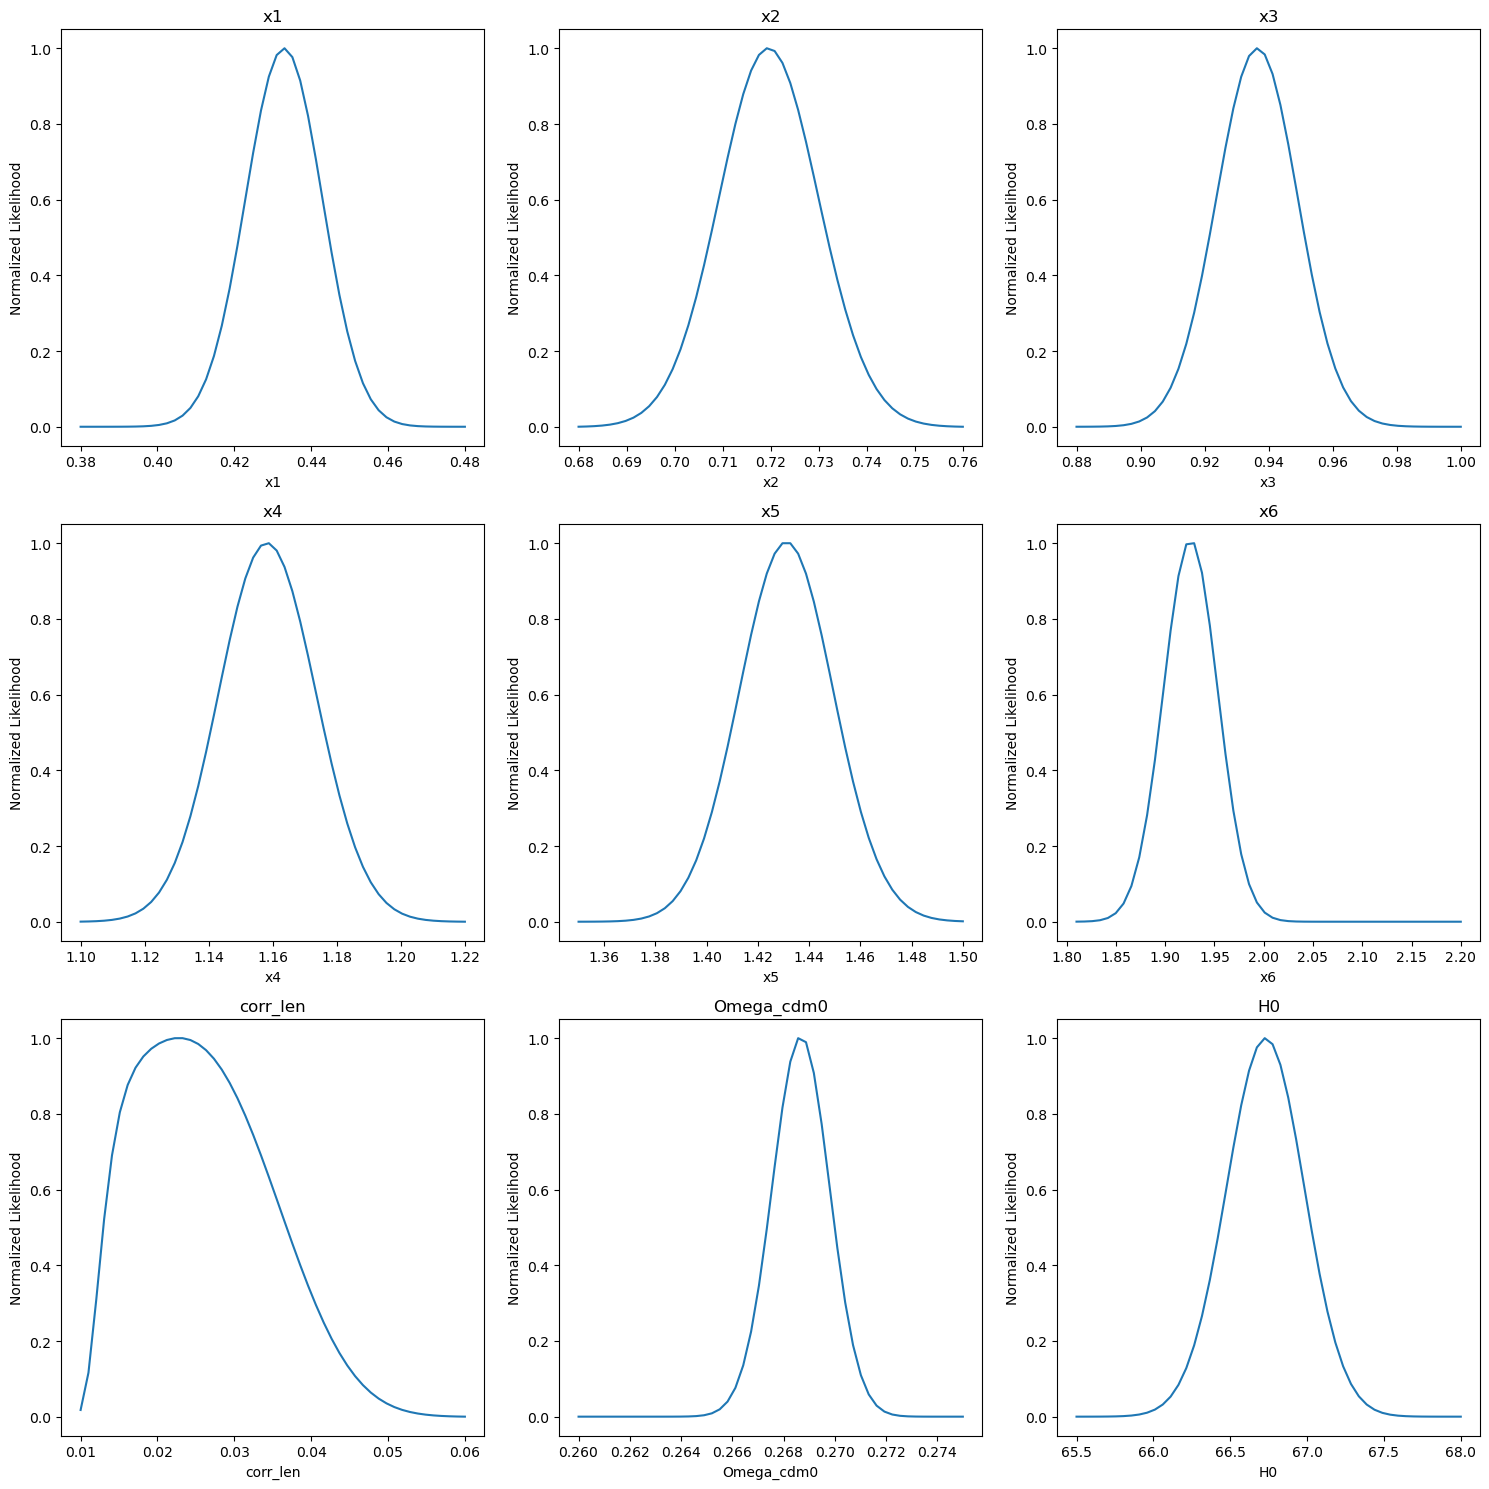

In [62]:
from tqdm import tqdm

fig, axes = plt.subplots(3,3, figsize=(15,15))
axes = axes.flatten()
oms = np.linspace(0.26, 0.275, 50)
H0s = np.linspace(65.5, 68, 50)
#om_b0s = np.linspace(0.02, 0.1, 50)
#w0s = np.linspace(-1.3, -0.5, 50)
#was = np.linspace(-0.4, 0.3, 50)
#ns_s = np.linspace(0.92, 1.0, 50)
#As_s = np.linspace(1.5e-9, 2.5e-9, 50)
#mnus = np.linspace(0.01, 0.2, 50)
#log10TAGNs = np.linspace(7.0, 8.5, 50)
#gamma_MGs = np.linspace(0.4, 0.7, 50)
x1 = np.linspace(0.38, 0.48, 50)
x2 = np.linspace(0.68, 0.76, 50)
x3 = np.linspace(0.88, 1.0, 50)
x4 = np.linspace(1.1, 1.22, 50)
x5 = np.linspace(1.35, 1.5, 50)
x6 = np.linspace(1.81, 2.2, 50)
corr_len = np.linspace(0.01, 0.06, 50)

#params = {'Omega_cdm0': oms, 'H0': H0s, 'Omega_b0': om_b0s, 'w0': w0s, 'wa': was, 'ns': ns_s, 'As': As_s, 'mnu': mnus, 'gamma_MG': gamma_MGs}
params_gp = {'x1': x1, 'x2': x2, 'x3': x3, 'x4': x4, 'x5': x5, 'x6': x6, 'corr_len': corr_len}
#keys = ['Omega_cdm0', 'H0', 'Omega_b0', 'w0', 'wa', 'ns', 'As', 'mnu', 'gamma_MG']
keys_gp = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'corr_len']
params_cosm = {'Omega_cdm0': oms, 'H0': H0s}
keys_cosm = ['Omega_cdm0', 'H0']
for key_gp, ax in zip(keys_gp, axes[:len(keys_gp)]):
    print(f"\n🔄 Scanning over {key_gp}")
    likelihood_curve = []

    for value in tqdm(params_gp[key_gp], desc=f"WL", ncols=80):
            # Update Omega_cdm0 parameter from omch2 and H0
    #    fid_cosm = fiducial_cosmology.copy()
        fid_gp = fiducial_gp.copy()
    #    fid_cosm[key_gp] = value
        fid_gp[key_gp] = value
        z_meds[0] = fid_gp['x1']
        z_meds[1] = fid_gp['x2']
        z_meds[2] = fid_gp['x3']
        z_meds[3] = fid_gp['x4']
        z_meds[4] = fid_gp['x5']
        z_meds[5] = fid_gp['x6']
        priors_like, predictions_like = build_gp_nz(n_meds, z_meds, fid_gp['corr_len'], z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)
        my_dndz_norm_gp_loop = resample_dndz_gp(predictions_like, z_pred_res, myz)
            # Compute log-likelihood
        like_instance.data.update({'dndz_she': my_dndz_norm_gp_loop})
        ll = like_instance.loglike(fiducial_cosmology | fiducial_nuisance)
        likelihood_curve.append(ll)
    
    # Convert log-likelihoods to likelihoods (exp) and normalize
    likelihood_curve = np.exp(likelihood_curve - np.max(likelihood_curve))
    
    # Plot
    ax.plot(params[key_gp], likelihood_curve, label='Cosmic shear')
    ax.set_title(key_gp)
    ax.set_xlabel(key_gp)
    ax.set_ylabel('Normalized Likelihood')

for key_cosm, ax in zip(keys_cosm, axes[len(keys_gp):]):
    print(f"\n🔄 Scanning over {key_cosm}")
    likelihood_curve = []
    for value in tqdm(params_cosm[key_cosm], desc=f"WL", ncols=80):
        fid_cosm = fiducial_cosmology.copy()
        fid_cosm[key_cosm] = value
        ll = like_instance.loglike(fid_cosm | fiducial_nuisance)
        likelihood_curve.append(ll)
    likelihood_curve = np.exp(likelihood_curve - np.max(likelihood_curve))
    
    # Plot
    ax.plot(params_cosm[key_cosm], likelihood_curve, label='Cosmic shear')
    ax.set_title(key_cosm)
    ax.set_xlabel(key_cosm)
    ax.set_ylabel('Normalized Likelihood')
plt.tight_layout()
plt.savefig("likelihood_scan_gp.pdf", bbox_inches='tight')
plt.show()